In [8]:
import re
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
print("AI Resume Analyzer and Job Recommendation System")

AI Resume Analyzer and Job Recommendation System


In [9]:
skill_data = {
    "skill": [
        "python", "java", "c++", "c#", "javascript",
        "sql", "machine learning", "deep learning",
        "scikit-learn", "tensorflow", "pytorch",
        "data analysis", "pandas", "numpy", "excel",
        "power bi", "tableau", "html", "css", "react",
        "node.js", "git", "github", "communication",
        "problem solving", "teamwork", ".net", "flask",
        "django", "mongodb"
    ],
    "category": [
        "Programming", "Programming", "Programming",
        "Programming", "Programming", "Database",
        "AI and ML", "AI and ML", "AI and ML", "AI and ML",
        "AI and ML", "Data", "Data", "Data", "Data",
        "Data Visualization", "Data Visualization",
        "Web Development", "Web Development",
        "Web Development", "Web Development", "Tools",
        "Tools", "Soft Skills", "Soft Skills", "Soft Skills",
        "Programming", "Web Development", "Web Development",
        "Database"
    ]
}
skills_df = pd.DataFrame(skill_data)
display(skills_df)
print("Total skills:", len(skills_df))

,skill,category
0,python,Programming
1,java,Programming
2,c++,Programming
3,c#,Programming
4,javascript,Programming
5,sql,Database
6,machine learning,AI and ML
7,deep learning,AI and ML
8,scikit-learn,AI and ML
9,tensorflow,AI and ML


Total skills: 30


In [10]:
job_roles = {
    "Python Developer": [
        "python", "sql", "git", "github", "problem solving"
    ],
    "Data Analyst": [
        "python", "sql", "excel", "power bi", "data analysis"
    ],
    "Machine Learning Engineer": [
        "python", "machine learning", "pandas", "numpy",
        "scikit-learn"
    ],
    "Web Developer": [
        "html", "css", "javascript", "react", "node.js"
    ],
    "Data Scientist": [
        "python", "sql", "machine learning", "pandas",
        "numpy", "data analysis"
    ]
}
def extract_skills(text):
    text = text.lower()
    found_skills = []
    for skill in skills_df["skill"]:
        pattern = r"(?<![a-z0-9])" + re.escape(skill) + r"(?![a-z0-9])"
        if re.search(pattern, text):
            found_skills.append(skill)
    return found_skills
def calculate_match(resume_text, required_skills):
    resume_skills = extract_skills(resume_text)
    common_skills = set(resume_skills) & set(required_skills)
    if not common_skills:
        return 0.0
    vectorizer = TfidfVectorizer()
    vectors = vectorizer.fit_transform([
        " ".join(resume_skills),
        " ".join(required_skills)
    ])
    return round(
        cosine_similarity(vectors[0:1], vectors[1:2])[0][0] * 100,
        2
    )
def recommend_roles(resume_text):
    results = []
    for role, required_skills in job_roles.items():
        results.append({
            "Job Role": role,
            "Match Score (%)": calculate_match(
                resume_text, required_skills
            )
        })
    results.sort(
        key=lambda item: item["Match Score (%)"],
        reverse=True
    )
    return pd.DataFrame(results[:3])
print("Job roles loaded:", len(job_roles))
display(pd.DataFrame([
    {"Job Role": role, "Required Skills": ", ".join(skills)}
    for role, skills in job_roles.items()
]))

Job roles loaded: 5


,Job Role,Required Skills
0,Python Developer,"python, sql, git, github, problem solving"
1,Data Analyst,"python, sql, excel, power bi, data analysis"
2,Machine Learning Engineer,"python, machine learning, pandas, numpy, sciki..."
3,Web Developer,"html, css, javascript, react, node.js"
4,Data Scientist,"python, sql, machine learning, pandas, numpy, ..."


In [11]:
sample_resume = """
Name: Alex Kumar
Education: B.Tech in Computer Science
Technical Skills: Python, SQL, Machine Learning, Pandas, NumPy, Scikit-learn, Excel, Data Analysis, Git, GitHub
Projects:
Built a machine learning model for predicting student performance
Performed data analysis using Python and Pandas
Created reports from structured datasets using SQL and Excel
Soft Skills:
Problem Solving, Communication, Teamwork.
"""

extracted_skills = extract_skills(sample_resume)
print("EXTRACTED SKILLS")
print(", ".join(extracted_skills))
recommendations = recommend_roles(sample_resume)
print("\nTOP 3 JOB RECOMMENDATIONS")
display(recommendations)

# Display skills missing for a selected role
selected_role = "Machine Learning Engineer"
required_skills = job_roles[selected_role]
missing_skills = [
    skill for skill in required_skills
    if skill not in extracted_skills
]
print("\nSELECTED ROLE:", selected_role)
print("MISSING SKILLS:", ", ".join(missing_skills)
      if missing_skills else "None")
print("\nLEARNING ROADMAP")
for skill in missing_skills:
    print(f"- Learn the basics of {skill}")
    print(f"  Practice: Complete a small project using {skill}")

EXTRACTED SKILLS
python, sql, machine learning, scikit-learn, data analysis, pandas, numpy, excel, git, github, communication, problem solving, teamwork

TOP 3 JOB RECOMMENDATIONS


,Job Role,Match Score (%)
0,Data Scientist,55.71
1,Machine Learning Engineer,51.15
2,Python Developer,46.52



SELECTED ROLE: Machine Learning Engineer
MISSING SKILLS: None

LEARNING ROADMAP


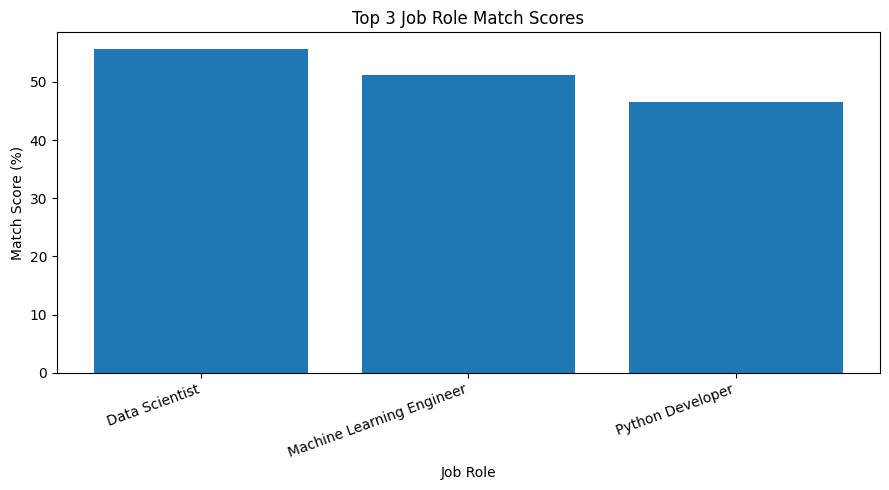

AI RESUME ANALYZER - ANALYSIS REPORT

EXTRACTED SKILLS
python, sql, machine learning, scikit-learn, data analysis, pandas, numpy, excel, git, github, communication, problem solving, teamwork

TOP 3 JOB RECOMMENDATIONS
Data Scientist: 55.71% match
Machine Learning Engineer: 51.15% match
Python Developer: 46.52% match

SELECTED TARGET ROLE: Machine Learning Engineer
MISSING SKILLS
None

Note: Match scores are estimates, not probabilities of employment.

Download your report below:


/content/resume_analysis_report.txt

In [12]:
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
# 1. Display a chart of the recommended job roles
plt.figure(figsize=(9, 5))
plt.bar(
    recommendations["Job Role"],
    recommendations["Match Score (%)"]
)
plt.title("Top 3 Job Role Match Scores")
plt.xlabel("Job Role")
plt.ylabel("Match Score (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
# 2. Create a downloadable text report
report_lines = [
    "AI RESUME ANALYZER - ANALYSIS REPORT",
    "",
    "EXTRACTED SKILLS",
    ", ".join(extracted_skills) if extracted_skills else "None",
    "",
    "TOP 3 JOB RECOMMENDATIONS",
]
for _, row in recommendations.iterrows():
    report_lines.append(
        f"{row['Job Role']}: {row['Match Score (%)']}% match"
    )
report_lines.extend([
    "",
    f"SELECTED TARGET ROLE: {selected_role}",
    "MISSING SKILLS",
    ", ".join(missing_skills) if missing_skills else "None",
    "",
    "Note: Match scores are estimates, not probabilities of employment."
])
report_content = "\n".join(report_lines)
with open("resume_analysis_report.txt", "w", encoding="utf-8") as file:
    file.write(report_content)
print(report_content)
print("\nDownload your report below:")
display(FileLink("resume_analysis_report.txt"))